In [5]:
%run ../notebooks/Preprocessing/Preprocessing.ipynb

--------------PREPROCESSING:  ORIGINAL --------------


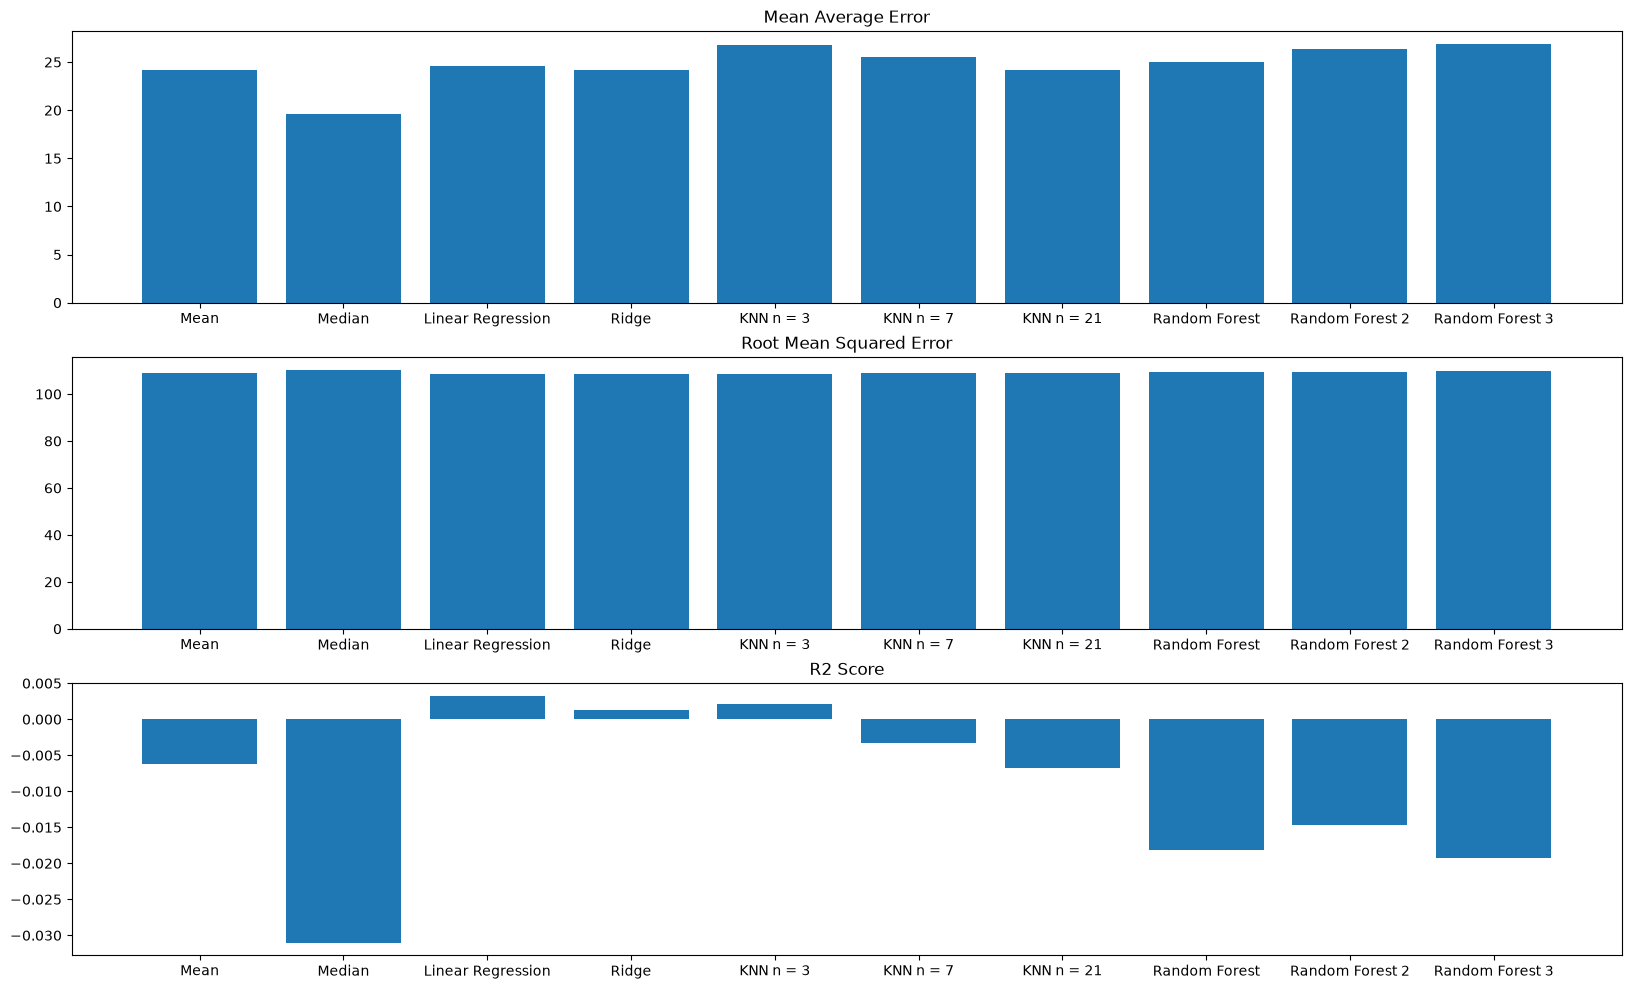

--------------PREPROCESSING:  ALL --------------


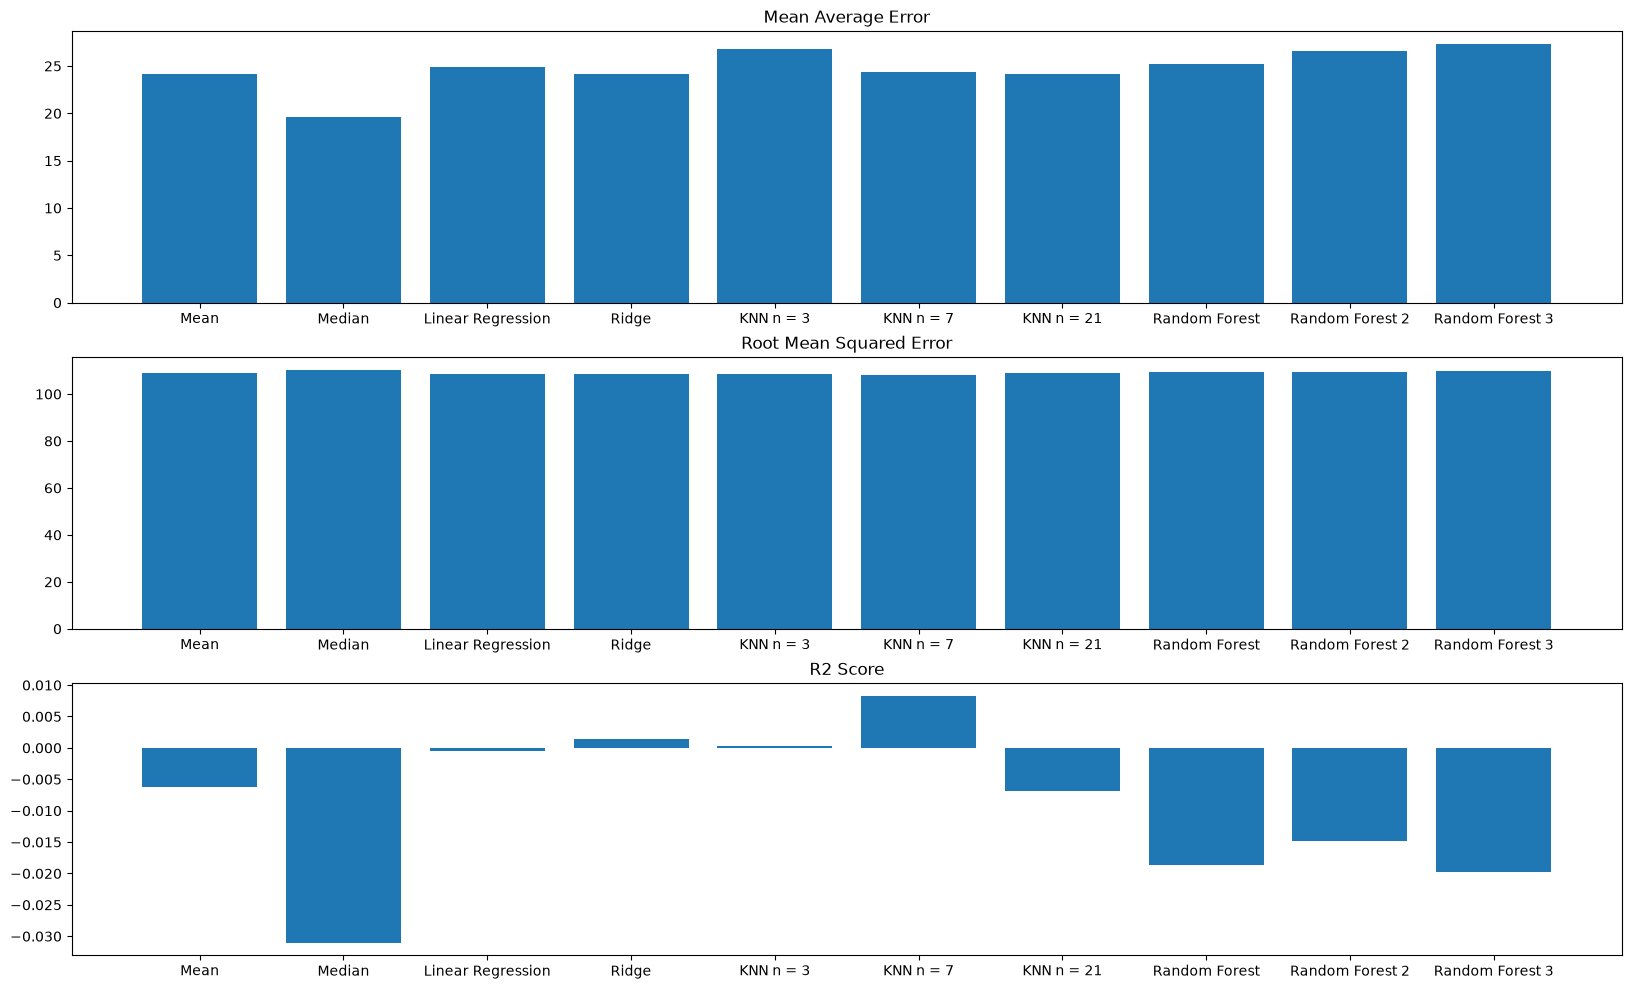

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------


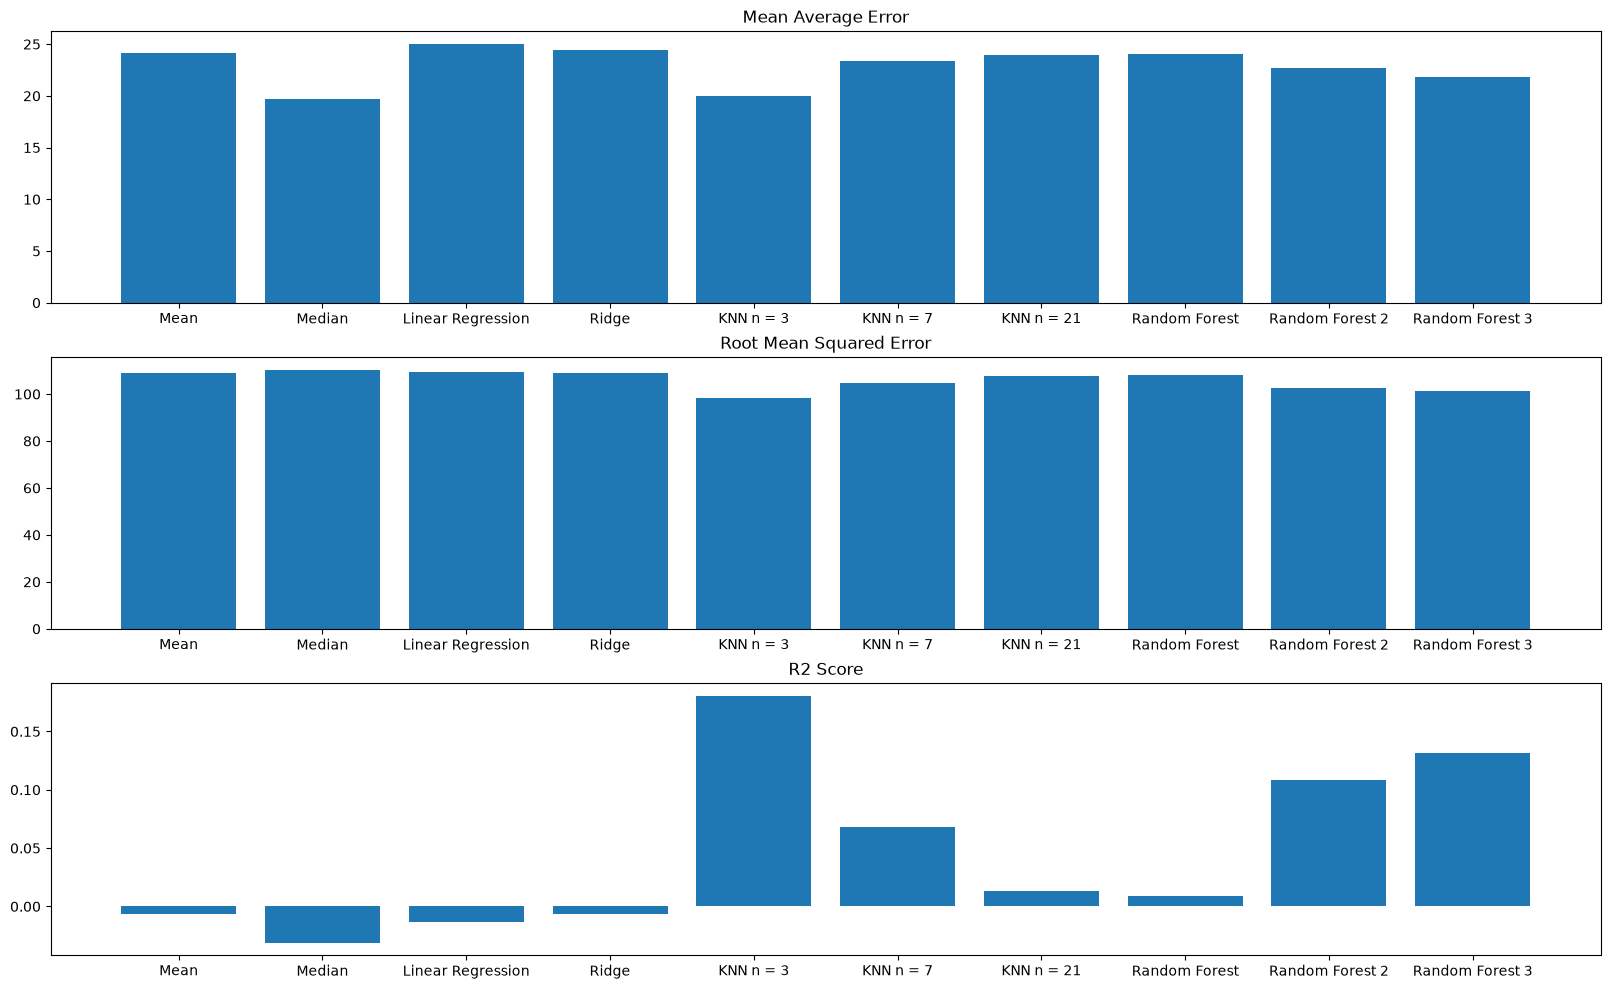

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------


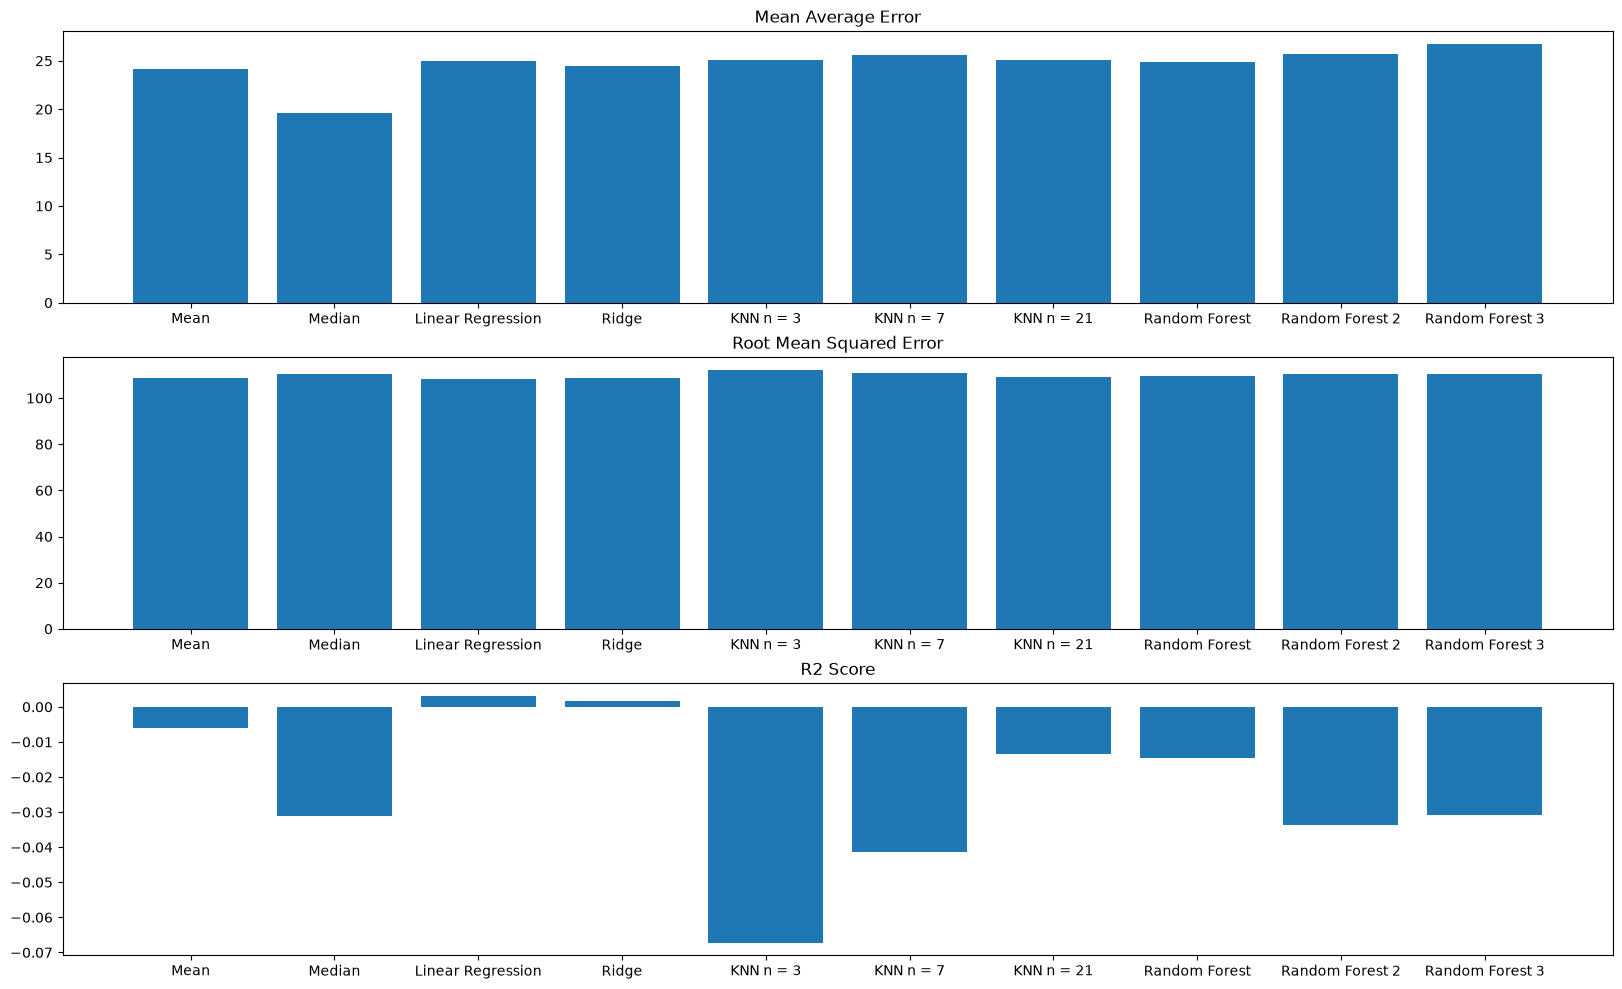

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

# Trying Different Models and preprocessing pipelines using train test split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []
    # Run all of the models and print out their results
    for name, model in models.items():
        model = make_pipeline(preprocessing, model)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        mae = mean_absolute_error(y_test, pred)
        rmse = root_mean_squared_error(y_test, pred)
        r2 = r2_score(y_test, pred)
    
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)
    
        #print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

    #Plot Results
    plt.figure(figsize={len(models.keys()) * 2,12}) ##Figure is dynamically sized to allow for more models to be added as needed
    
    plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(models.keys())),models.keys())
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(models.keys())),models.keys())

    plt.show()